# Gradient draws and 2D fields

**Kernel:** `python3`, the default Python (3.10 or newer) with labfigs installed. Choose it before running.

**Shows:** two separate figures on synthetic data (no inference is run).

1. The same posterior draws once per `gradient=` option of `lf.paths`. With a gradient, each draw is
   coloured by how far it sits from the median, so no interval is drawn.
2. One field per ramp as a heat map, and a signed field whose colours are centred on zero.

**Graph types:** draws coloured by distance from the median (`lf.paths`), heat maps (`lf.heatmap`).

**Writes:** `gradient_draws.svg` and `field.svg` next to this notebook.

**To tweak:** change the capitalised settings at the top of a **Figure** cell and re-run that cell.

**To run it all:** `jupyter nbconvert --to notebook --execute --inplace field.ipynb`, which also saves the figures in this notebook.

In [1]:
import numpy as np
from matplotlib.colors import to_rgba_array

import labfigs as lf

lf.use()
rng = np.random.default_rng(1)

## Data for the draws

Synthetic; swap this cell for your own loading.

- `x`: positions along the x axis, length 200
- `true_curve`: the true function at `x`
- `draws`: posterior draws, shape `(2000, len(x))`, one row per draw

In [2]:
x = np.linspace(0, 1, 200)
k = np.arange(1, 6)[None, :, None]
waves = rng.normal(size=(2000, 5, 1)) / k * np.sin(np.pi * k * x + rng.uniform(0, 2 * np.pi, (2000, 5, 1)))
true_curve = np.sin(2 * np.pi * x)
draws = true_curve + 0.35 * waves.sum(1)

## Figure 1: gradient draws

Settings at the top of the cell:

- `NAME`: file name of the figure, without `.svg`
- `WIDTH`, `PANEL_ASPECT`: figure width in inches, and the height of one panel divided by its width
- `ROWS`, `COLUMNS`: shape of the grid; it needs one panel per entry of `GRADIENTS`
- `GRADIENTS`: one panel each. `False` is flat draws in one colour. A ramp or scheme name, a single colour,
  a Wada number or a list of colours gives one colour per distance from the median.
- `DRAWS_LABEL`: legend entry of the draws
- `X_LABEL`, `X_TICKS` and `Y_LABEL`, `Y_TICKS`: the shared axes

PosixPath('gradient_draws.svg')

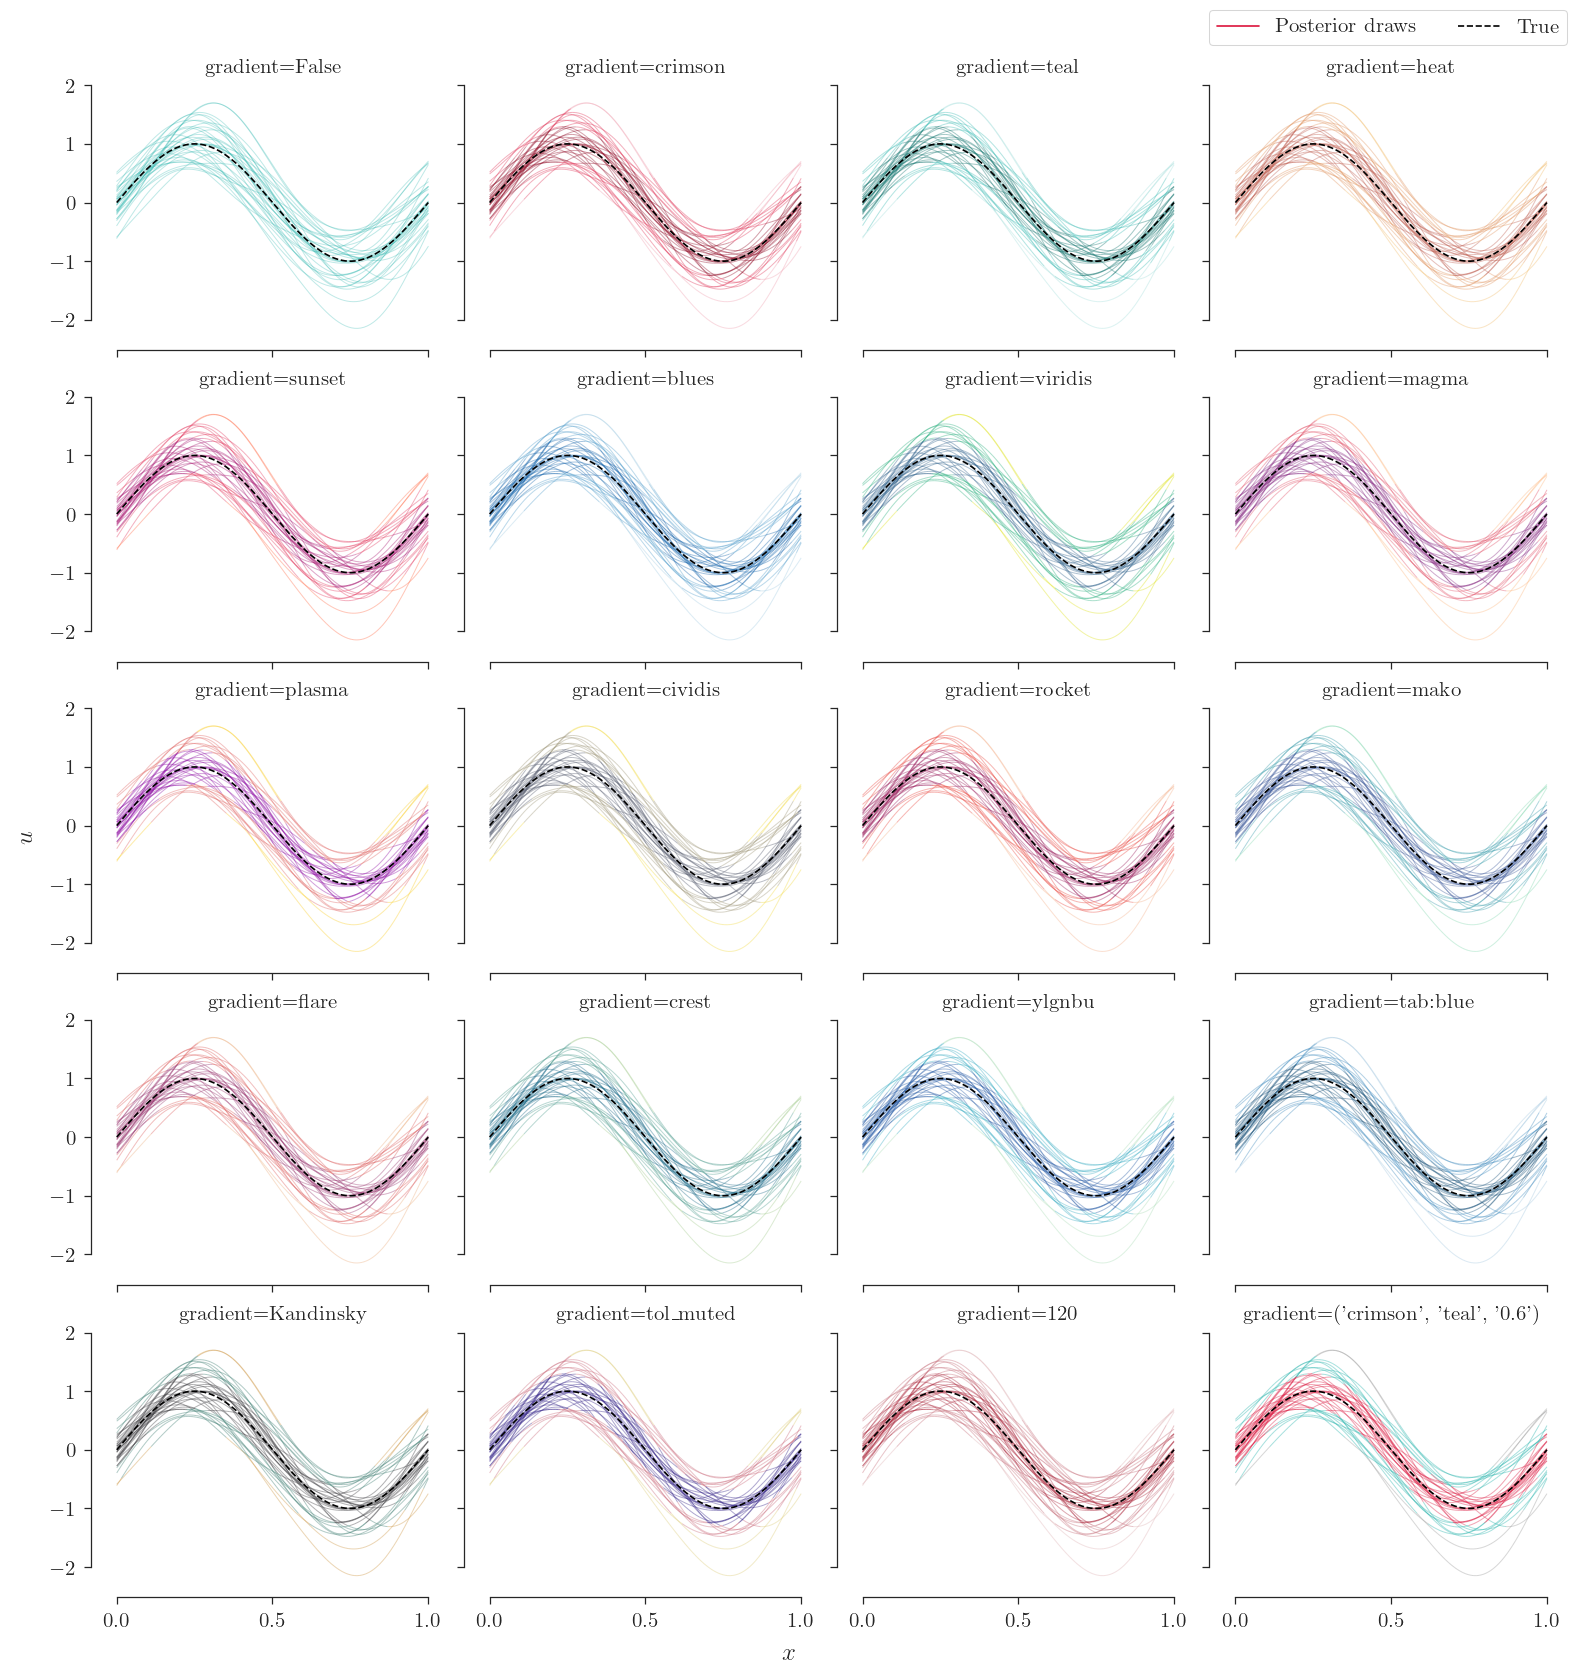

In [3]:
NAME = "gradient_draws"
WIDTH, PANEL_ASPECT = 10.4, 0.75
ROWS, COLUMNS = 5, 4
GRADIENTS = (False, *lf.RAMPS, "tab:blue", "Kandinsky", "tol_muted", 120, ("crimson", "teal", "0.6"))
DRAWS_LABEL = "Posterior draws"
X_LABEL, X_TICKS = "$x$", [0, 0.5, 1]
Y_LABEL, Y_TICKS = "$u$", [-2, -1, 0, 1, 2]

fig, draw_axes = lf.subplots(ROWS, COLUMNS, width=WIDTH, aspect=PANEL_ASPECT, sharex=True, sharey=True)
for ax, gradient in zip(draw_axes.flat, GRADIENTS):
    lf.paths(ax, x, draws, gradient=gradient, label=DRAWS_LABEL)
    lf.truth(ax, x, true_curve, ls="--")
    ax.set(title=f"gradient={gradient}", xticks=X_TICKS, yticks=Y_TICKS)
fig.supxlabel(X_LABEL)
fig.supylabel(Y_LABEL)
lf.legend_above(fig)
lf.save(fig, NAME)

## Data for the fields

Synthetic; swap this cell for your own loading.

- `xx`, `yy`: grids of the two coordinates, shape `(80, 80)`
- `fields`: one field per ramp, each on that grid with values between 0 and 1
- `signed`: a field with positive and negative values

In [4]:
xx, yy = np.meshgrid(np.linspace(0, 1, 80), np.linspace(0, 1, 80))
radius = np.hypot(xx - 0.5, yy - 0.5)
ripples = sum(np.cos(2 * np.pi * (a * xx + b * yy) + c) for a, b, c in rng.uniform(-2, 2, (6, 3)))
fields = [
    np.exp(-((xx - 0.5) ** 2 / 0.08 + (yy - 0.5) ** 2 / 0.015)),
    np.sin(np.pi * xx) * yy ** 2,
    np.exp(-((xx - 0.3) ** 2 + (yy - 0.6) ** 2) / 0.03) + 0.6 * np.exp(-((xx - 0.7) ** 2 + (yy - 0.3) ** 2) / 0.05),
    np.exp(-radius ** 2 / 0.02),
    np.exp(-(xx - yy) ** 2 / 0.02),
    np.sin(2 * np.pi * xx) * np.sin(2 * np.pi * yy) / 2 + 0.5,
    np.exp(-(radius - 0.3) ** 2 / 0.005),
    (ripples - ripples.min()) / np.ptp(ripples),
    radius / radius.max(),
    np.sin(3 * np.pi * (xx + yy)) ** 2,
    np.cos(12 * radius) ** 2,
    np.tanh((xx - 0.5 - 0.2 * np.sin(2 * np.pi * yy)) / 0.1) / 2 + 0.5,
    4 * xx * (1 - xx) * yy,
    xx,
]
signed = 0.08 * np.sin(5 * xx) * np.cos(4 * yy)

## Figure 2: heat maps

Settings at the top of the cell:

- `NAME`: file name of the figure, without `.svg`
- `WIDTH`, `PANEL_ASPECT`: figure width in inches, and the height of one panel divided by its width
- `ROWS`, `COLUMNS`: shape of the grid; it needs one panel per ramp plus one for the signed field
- `RAMPS`: colour ramp of each panel, in order; any ramp or scheme name
- `VALUE_RANGE`: values at the two ends of every colour bar
- `SIGNED_TITLE`: title of the last panel, whose colours are centred on zero
- `X_LABEL`, `Y_LABEL`, `TICKS`: the shared axes

PosixPath('field.svg')

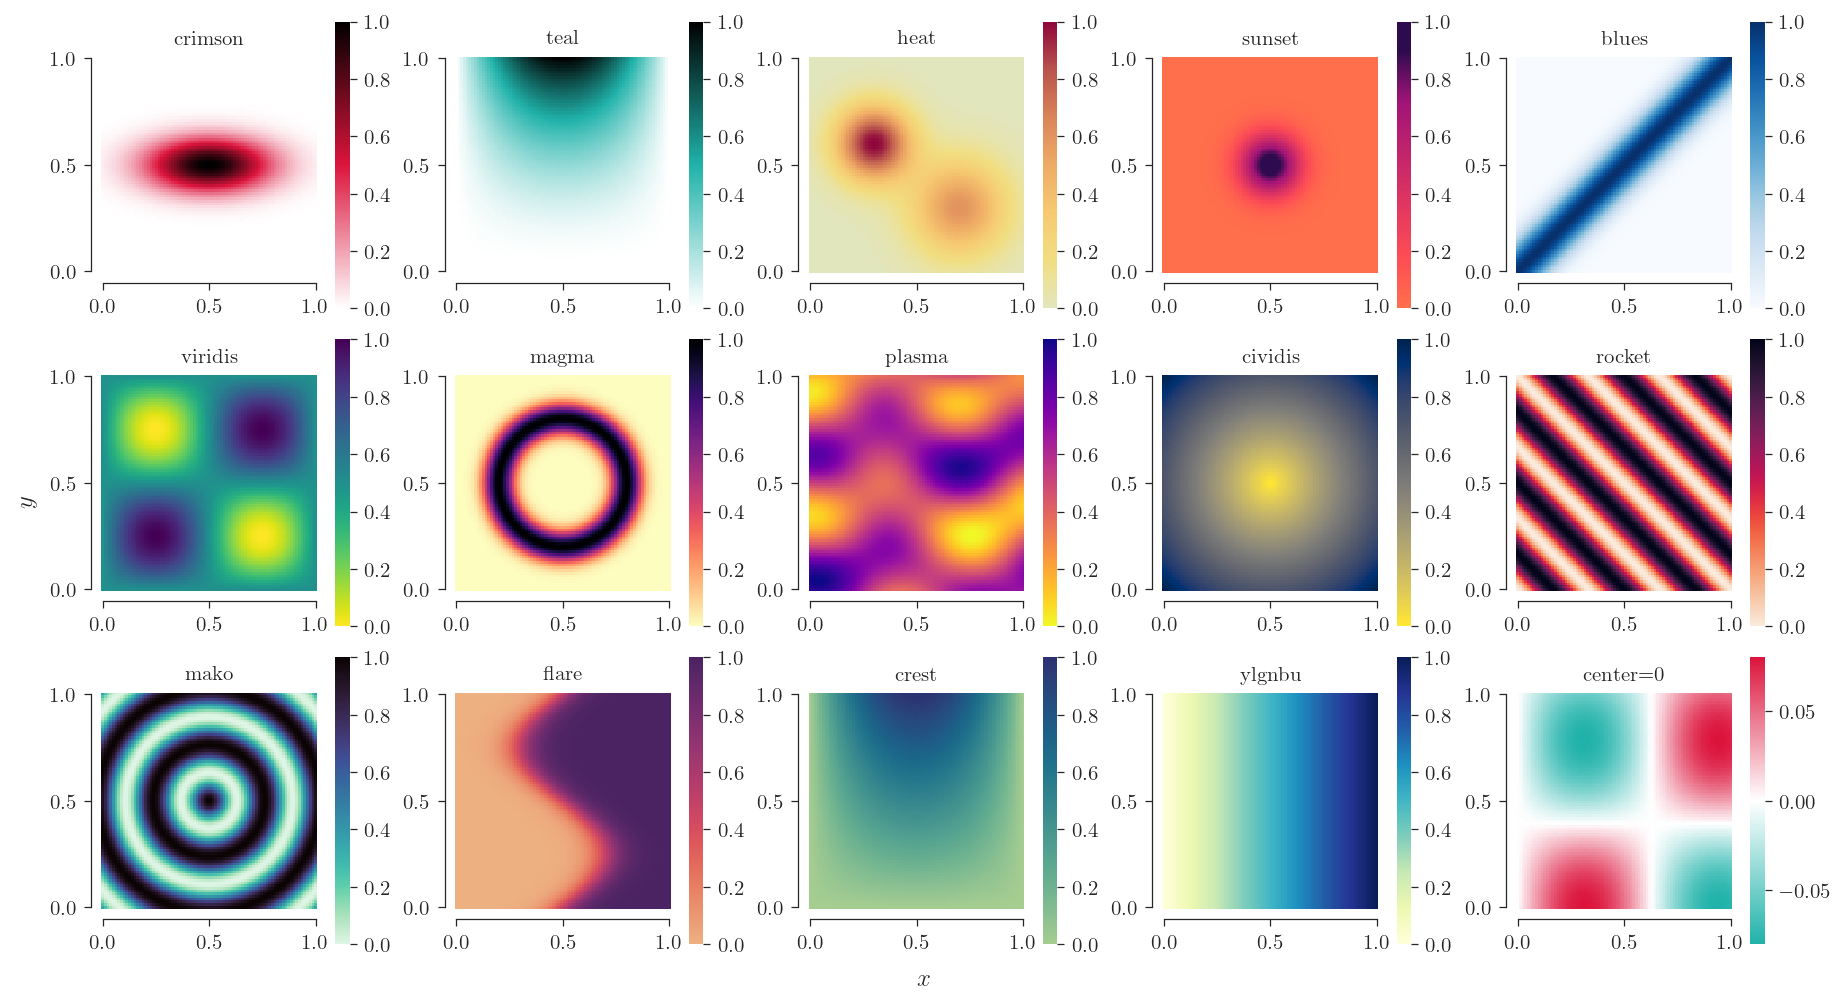

In [5]:
NAME = "field"
WIDTH, PANEL_ASPECT = 12.2, 0.9
ROWS, COLUMNS = 3, 5
RAMPS = tuple(lf.RAMPS)
VALUE_RANGE = (0, 1)
SIGNED_TITLE = "center=0"
X_LABEL, Y_LABEL, TICKS = "$x$", "$y$", [0, 0.5, 1]

low, high = VALUE_RANGE
panels = [(name, z, {"ramp": name, "vmin": low, "vmax": high}) for name, z in zip(RAMPS, fields, strict=True)]
panels.append((SIGNED_TITLE, signed, {"center": 0}))
fig, field_axes = lf.subplots(ROWS, COLUMNS, width=WIDTH, aspect=PANEL_ASPECT, n=len(panels))
for ax, (title, z, options) in zip(field_axes.flat, panels):
    lf.heatmap(ax, xx, yy, z, **options)
    ax.set(title=title, xticks=TICKS, yticks=TICKS, aspect="equal")
fig.supxlabel(X_LABEL)
fig.supylabel(Y_LABEL)
lf.save(fig, NAME)

## Checks

Fails if flat draws gain an interval in the legend, if `lf.steps` stops returning the colours it is given,
or if two heat maps share a ramp. Nothing to tweak.

In [6]:
assert not any("interval" in label for ax in draw_axes.flat for label in ax.get_legend_handles_labels()[1])
own = to_rgba_array(lf.COMBOS["Kandinsky"])
assert all(np.abs(own - colour).max(1).min() < 0.01 for colour in lf.steps("Kandinsky")) and len(lf.steps(120)) == 3
assert np.allclose(lf.steps(GRADIENTS[-1]), to_rgba_array(GRADIENTS[-1]), atol=0.01)
assert np.allclose(lf.steps("heat"), lf.HEAT([0.8, 0.6, 0.4]))
assert len({ax.collections[0].cmap.name for ax in field_axes.flat}) == field_axes.size